## Read Oxford-IIIT Pets dataset


The dataset is part of TensorFlow datasets.
Version 3 and higher of the dataset has ground truth
segmentation masks.

The dataset already contains test and train splits.

In [1]:
import tensorflow_datasets as tfds
import tensorflow as tf
dataset, info = tfds.load('oxford_iiit_pet:3.*.*', with_info=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...:   0%|          | 0/3680 [00:00<?, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/3.2.0.incomplete6MEVSY/oxford_iiit_pet-train.tfrecord*...:…

Generating test examples...:   0%|          | 0/3669 [00:00<?, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/3.2.0.incomplete6MEVSY/oxford_iiit_pet-test.tfrecord*...: …

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/3.2.0. Subsequent calls will reuse this data.


When loading an image:
* Resize the image and mask to 128x128
* Scale the image to [0,1]
* Create input_mask labels. The original segmentation mask consists of {1,2,3} for background, outline, and interior respectively. Subtract 1 to get class indexes of {0,1,2}.


In [2]:
#create a dictionary like object to hold input image and mask
"""data = {
    'image': image_data,  # 'image_data' is the input image data
    'segmentation_mask': mask_data  #  'mask_data' is the segmentation mask data
}"""

def read_and_preprocess(data):
    #Resize the img and mask
    input_image = tf.image.resize(data['image'], (128, 128))
    input_mask = tf.image.resize(data['segmentation_mask'], (128, 128))

    #rescale the image to (0,1) and mask to corresponding pixel labels
    input_image = tf.image.convert_image_dtype(input_image, tf.float32) # [0,1]
    input_mask -= 1 # {1,2,3} to {0,1,2}

    return input_image, input_mask

In [3]:
train = dataset['train'].map(read_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test = dataset['test'].map(read_and_preprocess)

## Display some example images and their labels

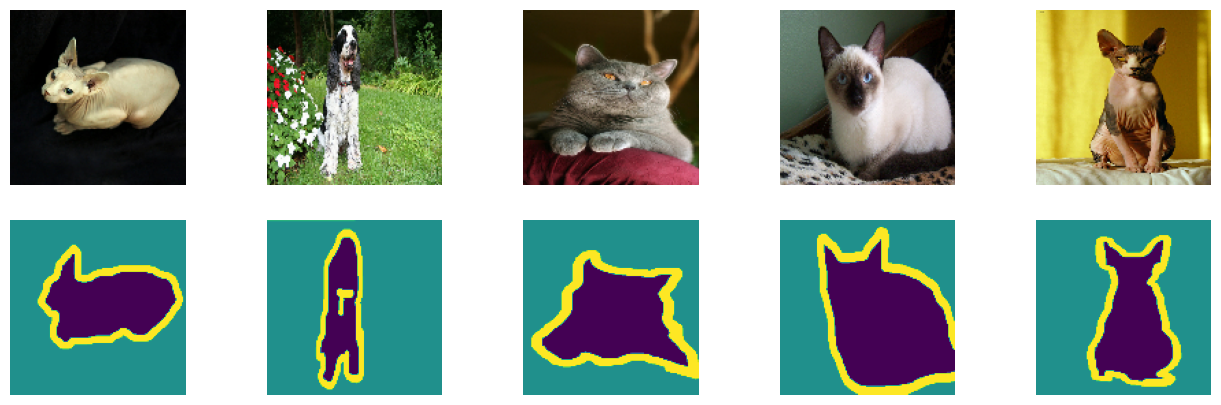

In [4]:
import matplotlib.pylab as plt
import numpy as np
f, ax = plt.subplots(2, 5, figsize=(16,5))
for idx, (img, mask) in enumerate(train.take(5)):
  ax[0, idx].imshow(tf.keras.preprocessing.image.array_to_img(img))
  ax[0, idx].axis('off')
  mask = tf.reshape(mask, [128, 128])
  ax[1, idx].imshow(mask.numpy())
  ax[1, idx].axis('off')

## Modified U-Net
The model being used here is a modified [U-Net](https://link.springer.com/content/pdf/10.1007%2F978-3-319-24574-4_28.pdf).
A U-Net typically consists of an encoder
which downsamples an image to an encoding,
and a mirrored decoder which upsamples the encoding
back to the desired mask. The decoder blocks have a number of skip connections
that directly connect the encoder blocks to the decoder.

Doing this from scratch requires a lot of trainable parameters and is better done using Generative
Adversarial Networks (GANs)
In this notebook, a pretrained MobileNetV2 be used to
create the encoding and a set of upsampling layers to
get back to the desired mask.
PUlled out layers with the
desired sizes so that the upsampling skip layers use
corresponding weights from the pretrained models.

To make the dataset go a little bit farther,
training dataset is augemnted to flip the images.

The output consists of 3 channels. This is because of 3 possible labels for each pixel (background, outline, interior). It is like a multi-classification problem with three possible classes.

In [5]:
BATCH_SIZE = 64
BUFFER_SIZE = 1000

def augment(img, mask):
  if tf.random.uniform(()) > 0.5:
    img = tf.image.flip_left_right(img)
    mask = tf.image.flip_left_right(mask)
  return img, mask

train_dataset = train.cache().map(augment).shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()
train_dataset = train_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

test_dataset = test.batch(BATCH_SIZE)

In [6]:
TRAIN_LENGTH = info.splits['train'].num_examples
STEPS_PER_EPOCH = TRAIN_LENGTH // BATCH_SIZE
OUTPUT_CHANNELS = 3

In [7]:
base_model = tf.keras.applications.MobileNetV2(input_shape=[128, 128, 3], include_top=False)

# Use the activations of these layers to form skip connections
layer_names = [
    'block_1_expand_relu',   # 64x64
    'block_3_expand_relu',   # 32x32
    'block_6_expand_relu',   # 16x16
    'block_13_expand_relu',  # 8x8
    'block_16_project',      # 4x4
]
base_model_outputs = [base_model.get_layer(name).output for name in layer_names]

# Create the feature extraction model
down_stack = tf.keras.Model(inputs=base_model.input, outputs=base_model_outputs,
                            name='pretrained_mobilenet')

down_stack.trainable = False

9406464/9406464 [==============================] - 1s 0us/step


The decoder/upsampler is a series of upsample blocks.
Conv2DTranspose is what does the upsampling.
We also add batchnorm and relu.

In [8]:
def upsample(filters, size, name):
  return tf.keras.Sequential([
     tf.keras.layers.Conv2DTranspose(filters, size, strides=2, padding='same'),
     tf.keras.layers.BatchNormalization(),
     tf.keras.layers.ReLU()
  ], name=name)

up_stack = [
    upsample(512, 3, 'upsample_4x4_to_8x8'),
    upsample(256, 3, 'upsample_8x8_to_16x16'),
    upsample(128, 3, 'upsample_16x16_to_32x32'),
    upsample(64, 3,  'upsample_32x32_to_64x64')
]

In [9]:
import re

def unet_model(output_channels):
  inputs = tf.keras.layers.Input(shape=[128, 128, 3], name='input_image')

  # Downsampling through the model
  skips = down_stack(inputs)
  x = skips[-1]
  skips = reversed(skips[:-1])

  # Upsampling and establishing the skip connections
  for idx, (up, skip) in enumerate(zip(up_stack, skips)):
    x = up(x)
    concat = tf.keras.layers.Concatenate(name='expand_{}'.format(idx))
    x = concat([x, skip])

  # This is the last layer of the model
  last = tf.keras.layers.Conv2DTranspose(
      output_channels, 3, strides=2,
      padding='same')  #64x64 -> 128x128

  x = last(x)

  return tf.keras.Model(inputs=inputs, outputs=x)

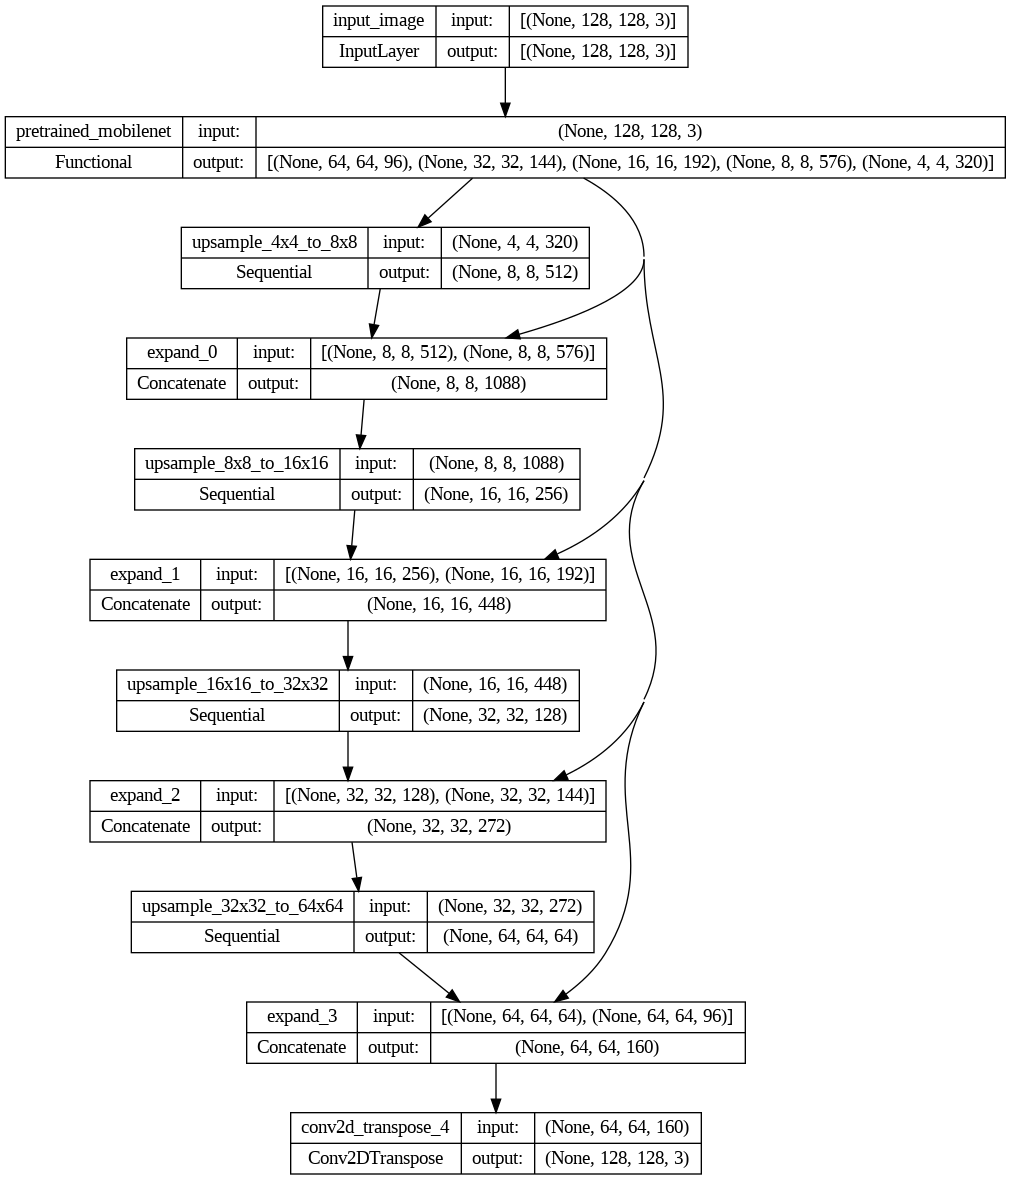

In [10]:
model = unet_model(OUTPUT_CHANNELS)
tf.keras.utils.plot_model(model, show_shapes=True)

## Train the model

We treat this as a multi-class prediction problem.
So, the loss function used is SparseCategoricalCrossentropy
and the metric is accuracy.

In [11]:
model = unet_model(OUTPUT_CHANNELS)
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [13]:
# Assign to the pixel the label with the highest probability
def create_mask(pred_mask):
  pred_mask = tf.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]

Helper functions to see model output as it is training

In [14]:
# display helper functions
def display(display_list):
  plt.figure(figsize=(15, 15))

  title = ['Input Image', 'True Mask', 'Predicted Mask']

  for i in range(len(display_list)):
    plt.subplot(1, len(display_list), i+1)
    plt.title(title[i])
    plt.imshow(tf.keras.preprocessing.image.array_to_img(display_list[i]))
    plt.axis('off')
  plt.show()

def show_predictions(dataset, num):
  for image, mask in dataset.take(num):
    pred_mask = model.predict(image)
    display([image[0], mask[0], create_mask(pred_mask)])

1/1 [==============================] - 9s 9s/step


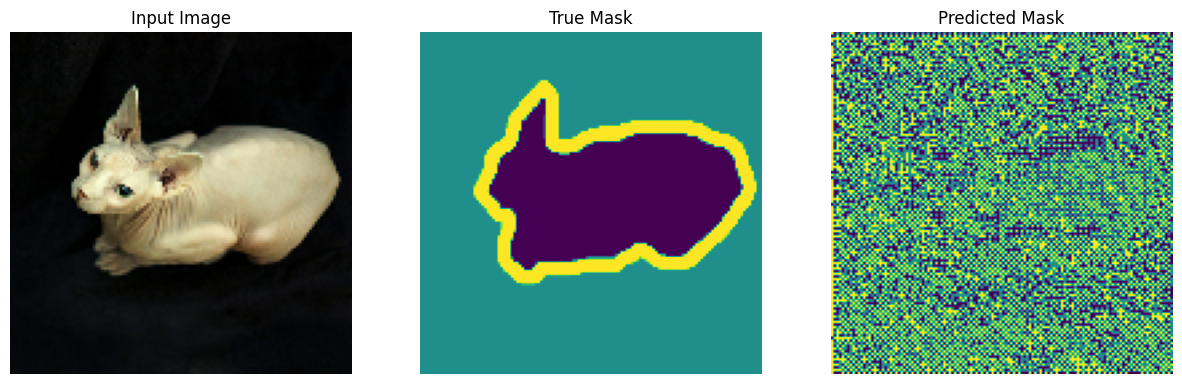

In [15]:
# before the model is trained
show_predictions(train.batch(1), 1)

To observe how the model improves while it is training we define a callback function to show the predictions when the epoch finishes.

In [16]:
# from IPython.display import clear_output
class DisplayCallback(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs=None):
    if epoch%5 == 0:
      # clear_output(wait=True) # if you want replace the images each time, uncomment this
      show_predictions(train.batch(1), 1)
      print ('\nSample Prediction after epoch {}\n'.format(epoch+1))

Epoch 1/20
1/1 [==============================] - 0s 24ms/step


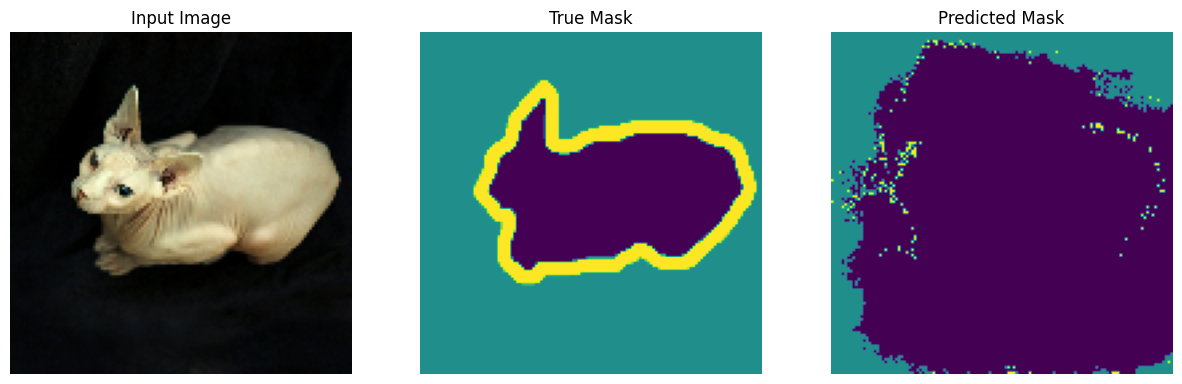


Sample Prediction after epoch 1

57/57 [==============================] - 30s 302ms/step - loss: 0.7625 - accuracy: 0.6715 - val_loss: 2.0564 - val_accuracy: 0.4668
Epoch 2/20
57/57 [==============================] - 11s 168ms/step - loss: 0.6107 - accuracy: 0.7432 - val_loss: 0.7960 - val_accuracy: 0.6511
Epoch 3/20
57/57 [==============================] - 9s 157ms/step - loss: 0.5879 - accuracy: 0.7529 - val_loss: 0.5904 - val_accuracy: 0.7528
Epoch 4/20
57/57 [==============================] - 9s 164ms/step - loss: 0.5726 - accuracy: 0.7602 - val_loss: 0.5791 - val_accuracy: 0.7571
Epoch 5/20
57/57 [==============================] - 9s 156ms/step - loss: 0.5624 - accuracy: 0.7643 - val_loss: 0.5925 - val_accuracy: 0.7511
Epoch 6/20
1/1 [==============================] - 0s 25ms/step


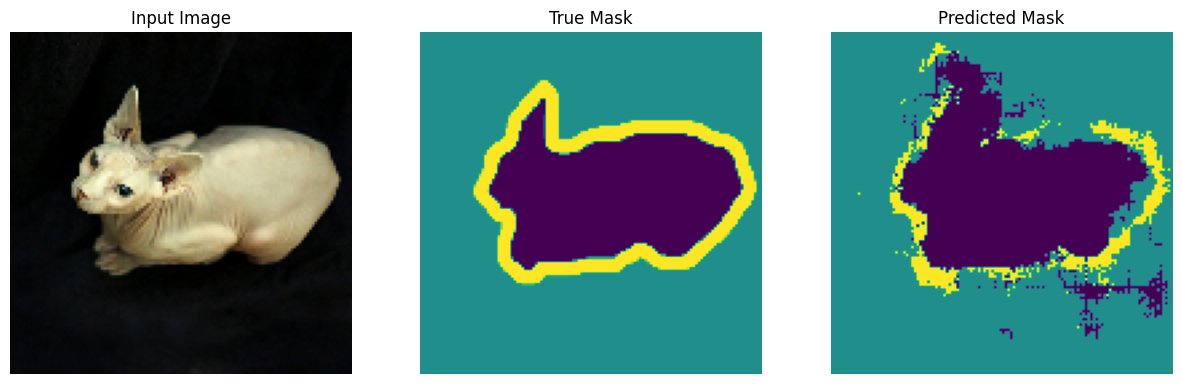


Sample Prediction after epoch 6

57/57 [==============================] - 12s 215ms/step - loss: 0.5512 - accuracy: 0.7697 - val_loss: 0.5692 - val_accuracy: 0.7602
Epoch 7/20
57/57 [==============================] - 9s 165ms/step - loss: 0.5424 - accuracy: 0.7729 - val_loss: 0.5653 - val_accuracy: 0.7627
Epoch 8/20
57/57 [==============================] - 11s 194ms/step - loss: 0.5365 - accuracy: 0.7759 - val_loss: 0.5661 - val_accuracy: 0.7612
Epoch 9/20
57/57 [==============================] - 10s 175ms/step - loss: 0.5316 - accuracy: 0.7777 - val_loss: 0.5471 - val_accuracy: 0.7711
Epoch 10/20
57/57 [==============================] - 9s 165ms/step - loss: 0.5317 - accuracy: 0.7784 - val_loss: 0.5522 - val_accuracy: 0.7667
Epoch 11/20
1/1 [==============================] - 0s 23ms/step


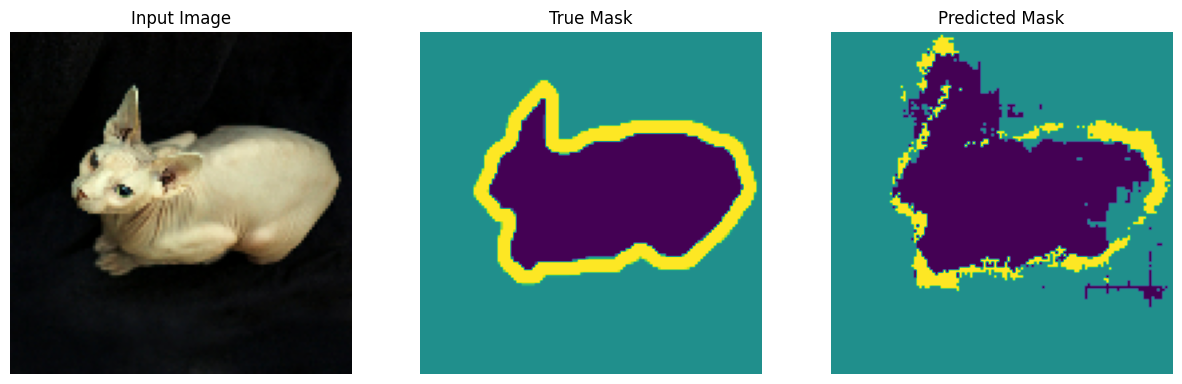


Sample Prediction after epoch 11

57/57 [==============================] - 12s 219ms/step - loss: 0.5232 - accuracy: 0.7815 - val_loss: 0.5964 - val_accuracy: 0.7486
Epoch 12/20
57/57 [==============================] - 12s 207ms/step - loss: 0.5206 - accuracy: 0.7829 - val_loss: 0.5471 - val_accuracy: 0.7707
Epoch 13/20
57/57 [==============================] - 10s 173ms/step - loss: 0.5140 - accuracy: 0.7854 - val_loss: 0.5344 - val_accuracy: 0.7781
Epoch 14/20
57/57 [==============================] - 9s 155ms/step - loss: 0.5121 - accuracy: 0.7860 - val_loss: 0.5379 - val_accuracy: 0.7757
Epoch 15/20
57/57 [==============================] - 9s 166ms/step - loss: 0.5059 - accuracy: 0.7887 - val_loss: 0.5423 - val_accuracy: 0.7761
Epoch 16/20
1/1 [==============================] - 0s 23ms/step


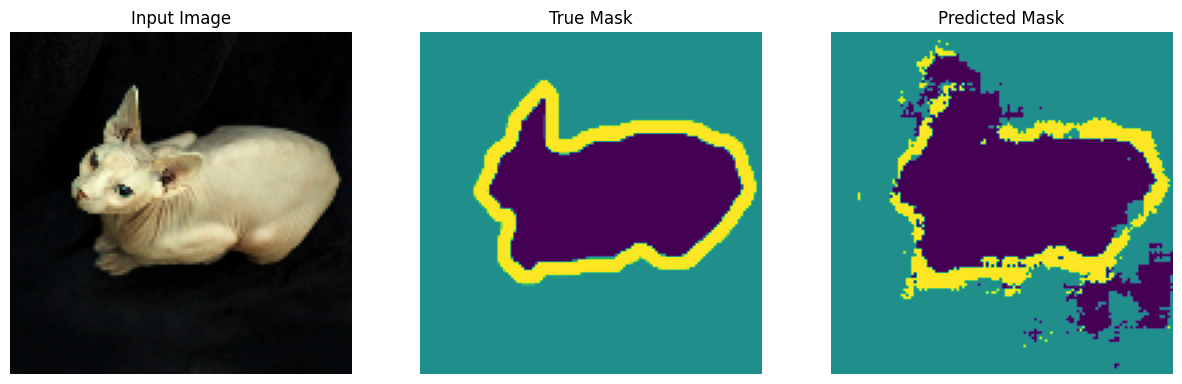


Sample Prediction after epoch 16

57/57 [==============================] - 10s 176ms/step - loss: 0.5033 - accuracy: 0.7897 - val_loss: 0.5430 - val_accuracy: 0.7756
Epoch 17/20
57/57 [==============================] - 10s 174ms/step - loss: 0.4970 - accuracy: 0.7925 - val_loss: 0.5405 - val_accuracy: 0.7742
Epoch 18/20
57/57 [==============================] - 9s 157ms/step - loss: 0.4935 - accuracy: 0.7938 - val_loss: 0.5432 - val_accuracy: 0.7779
Epoch 19/20
57/57 [==============================] - 9s 160ms/step - loss: 0.4939 - accuracy: 0.7936 - val_loss: 0.5345 - val_accuracy: 0.7793
Epoch 20/20
57/57 [==============================] - 9s 165ms/step - loss: 0.4851 - accuracy: 0.7973 - val_loss: 0.6003 - val_accuracy: 0.7601


In [17]:
EPOCHS = 20
VAL_SUBSPLITS = 5
VALIDATION_STEPS = info.splits['test'].num_examples//BATCH_SIZE//VAL_SUBSPLITS

model_history = model.fit(train_dataset, epochs=EPOCHS,
                          steps_per_epoch=STEPS_PER_EPOCH,
                          validation_steps=VALIDATION_STEPS,
                          validation_data=test_dataset,
                          callbacks=[DisplayCallback()])

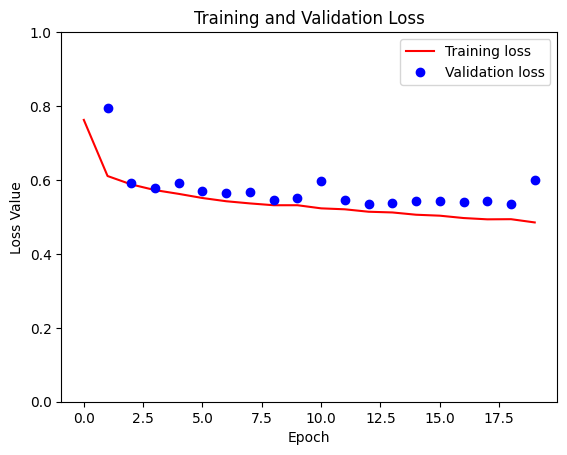

In [18]:
loss = model_history.history['loss']
val_loss = model_history.history['val_loss']

epochs = range(EPOCHS)

plt.figure()
plt.plot(epochs, loss, 'r', label='Training loss')
plt.plot(epochs, val_loss, 'bo', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss Value')
plt.ylim([0, 1])
plt.legend()
plt.show()

To improve the performance further:
* Train longer
* Use Mask-R CNN (next notebook)